In [1]:
import pandas as pd
import os

# os.chdir(os.path.dirname(os.path.abspath(__file__)))

In [84]:
fisheries = pd.read_csv('data/FL_Fisheries_Independent_Monitoring_Inshore_Stratified-Random_Sampling_Records.csv')

In [85]:
fisheries.columns

Index(['X', 'Y', 'OBJECTID', 'Reference', 'Sampling_Date', 'Latitude',
       'Longitude', 'Gear', 'Scientificname', 'Commonname', 'TotalNum',
       'avg_size', 'min_size', 'max_size', 'Shape', 'Export_Date'],
      dtype='str')

In [86]:
fisheries.shape

(1765226, 16)

In [87]:
tampa_bay = fisheries[fisheries['Reference'].str.contains("TBM")].reset_index()
tampa_bay = tampa_bay[['Reference', 'Sampling_Date', 'Gear', 'Commonname', 'TotalNum', 'avg_size', 'min_size', 'max_size']]

In [88]:
fisheries['Reference'].str[0:3].unique()

<StringArray>
['ANM', 'APM', 'BBM', 'CHM', 'CHX', 'CKM', 'CKX', 'CRM', 'CZM', 'EBM', 'EVM',
 'FBM', 'FWM', 'FWX', 'GLM', 'HIM', 'HSM', 'IRM', 'IRX', 'JXM', 'KYM', 'LBM',
 'PBM', 'SAM', 'SBM', 'SJM', 'TBD', 'TBM', 'TBX', 'TQM', 'TQX', 'WWM']
Length: 32, dtype: str

In [89]:
tampa_bay['Commonname'].unique()

<StringArray>
[       'Striped Burrfish',              'Naked Goby',
       'Atlantic Stingray',        'Leopard Searobin',
        'Scrawled Cowfish',             'Bay Anchovy',
        'Hardhead Catfish',               'Blue Crab',
       'Tidewater Mojarra',          'Lined Seahorse',
 ...
               'Flounders', 'Atlantic Calico Scallop',
         'Barred Searobin',   'Foureye Butterflyfish',
              'Filefishes',            'Nile Tilapia',
         'Reef Silverside',            'Reef Croaker',
              'filefishes',          'requiem sharks']
Length: 383, dtype: str

In [90]:
tampa_bay[tampa_bay['Commonname'] == 'Reef Croaker']['Sampling_Date'].unique()

<StringArray>
['2023/07/10 04:00:00+00']
Length: 1, dtype: str

In [91]:
counts = tampa_bay['Commonname'].value_counts()
keep = counts[counts > 30].index

filtered = tampa_bay[tampa_bay['Commonname'].isin(keep)]
filtered

,Reference,Sampling_Date,Gear,Commonname,TotalNum,avg_size,min_size,max_size
0,TBM1996011601,1996/01/16 05:00:00+00,300,Striped Burrfish,1,148.0,148.0,148.0
1,TBM1996011601,1996/01/16 05:00:00+00,300,Naked Goby,3,31.0,29.0,34.0
2,TBM1996011601,1996/01/16 05:00:00+00,300,Atlantic Stingray,1,247.0,247.0,247.0
3,TBM1996011601,1996/01/16 05:00:00+00,300,Leopard Searobin,20,49.0,38.0,90.0
4,TBM1996011602,1996/01/16 05:00:00+00,300,Scrawled Cowfish,5,68.0,19.0,139.0
...,...,...,...,...,...,...,...,...
409776,TBM2023123318,2023/12/13 05:00:00+00,5,Sheepshead Minnow,8,15.0,12.0,20.0
409777,TBM2023123318,2023/12/13 05:00:00+00,5,Silver Jenny,1,48.0,48.0,48.0
409778,TBM2023123318,2023/12/13 05:00:00+00,5,Eucinostomus,23,26.0,23.0,31.0
409779,TBM2023123318,2023/12/13 05:00:00+00,5,Goldspotted Killifish,11,36.0,19.0,46.0


In [92]:
filtered['Sampling_Date'] = pd.to_datetime(filtered['Sampling_Date'])

In [93]:
import matplotlib.pyplot as plt

In [94]:
filtered['Commonname'].unique()

<StringArray>
[ 'Striped Burrfish',        'Naked Goby', 'Atlantic Stingray',
  'Leopard Searobin',  'Scrawled Cowfish',       'Bay Anchovy',
  'Hardhead Catfish',         'Blue Crab', 'Tidewater Mojarra',
    'Lined Seahorse',
 ...
  'Roughneck Shrimp',          'Shelligs', 'Blackchin Tilapia',
   'Snapping Shrimp',          'Hardback',      'Crested Goby',
          'Scallops',     'Mayan Cichlid',  'Sheepshead Porgy',
       'Bay Scallop']
Length: 182, dtype: str

In [95]:
fish_specific = filtered[filtered['Commonname'] == 'Striped Burrfish']

In [96]:
fish_specific['Sampling_Date'].dtype

datetime64[us, UTC]

In [97]:
fish_specific['Sampling_Date'].value_counts()

Sampling_Date
2019-11-14 05:00:00+00:00    14
2023-11-17 05:00:00+00:00    13
2023-07-12 04:00:00+00:00    12
2010-07-20 04:00:00+00:00    11
2012-06-28 04:00:00+00:00    11
                             ..
2023-08-09 04:00:00+00:00     1
2023-09-13 04:00:00+00:00     1
2023-10-10 04:00:00+00:00     1
2023-10-05 04:00:00+00:00     1
2023-11-03 04:00:00+00:00     1
Name: count, Length: 2116, dtype: int64

In [100]:
fish_specific.columns

Index(['Reference', 'Sampling_Date', 'Gear', 'Commonname', 'TotalNum',
       'avg_size', 'min_size', 'max_size'],
      dtype='str')

In [98]:
fish_specific = fish_specific.groupby('Sampling_Date')[['Shape']].mean().reset_index()
fish_specific

KeyError: "Columns not found: 'Shape'"

In [17]:
fish_specific = fish_specific.set_index('Sampling_Date').sort_index()

In [ ]:
monthly_avg = fish_specific['Shape'].resample('YE').mean()

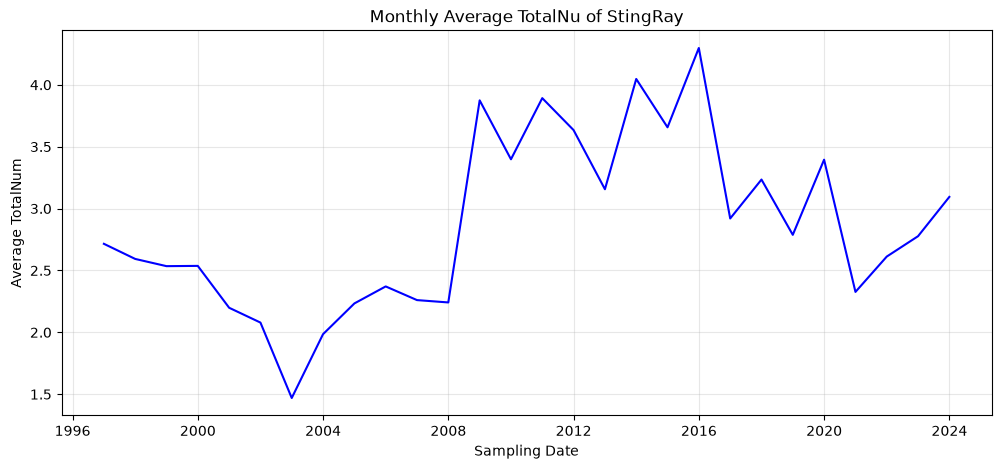

In [19]:
plt.figure(figsize=(12, 5))
plt.plot(monthly_avg.index, monthly_avg.values, color='blue', linewidth=1.5)
plt.title('Monthly Average TotalNu of StingRay')
plt.xlabel('Sampling Date')
plt.ylabel('Average TotalNum')
plt.grid(True, alpha=0.3)
plt.show()

In [20]:
seagrass = pd.read_csv('data/sgsegest.csv')
seagrass

,segment,acres,year
0,Boca Ciega Bay,6258.932576,1988
1,Hillsborough Bay,6.770810,1988
2,Lower Tampa Bay,5523.984360,1988
3,Manatee River,347.249089,1988
4,Middle Tampa Bay,5195.761701,1988
...,...,...,...
121,Terra Ceia Bay,993.461512,2024
122,Old Tampa Bay,3857.513304,2024
123,Manatee River,463.093884,2024
124,Lower Tampa Bay,8035.856071,2024


In [21]:
seagrass['year'].dtype

dtype('int64')

In [22]:
yearly_acrage = seagrass.groupby('year')[['acres']].sum().reset_index()

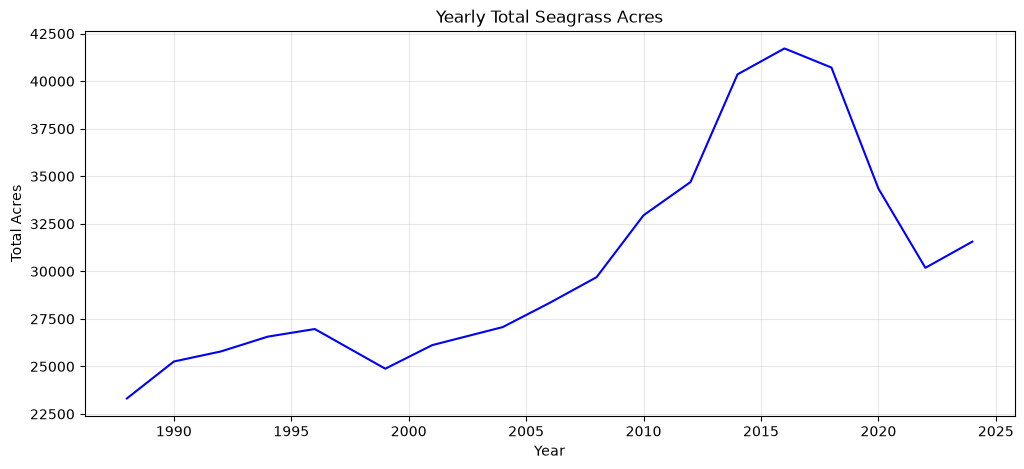

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_acrage['year'], yearly_acrage['acres'], color='blue', linewidth=1.5)
plt.title('Yearly Total Seagrass Acres')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()

In [45]:
water_quality = pd.read_csv('data/clean_water_quality.csv')

In [46]:
water_quality['SampleDate'].dtype

<StringDtype(storage='python', na_value=nan)>

In [47]:
water_quality['SampleDate'] = pd.to_datetime(water_quality['SampleDate'])

In [83]:
water_quality['WaterBodyName'].unique()

<StringArray>
[           'Hayes Bayou',         'Boca Ciega Bay',      'Clearwater Harbor',
       'Hillsborough Bay', 'Long Bayou/Cross Bayou',        'Lower Tampa Bay']
Length: 6, dtype: str

In [49]:
cleaned_water_quality = water_quality.dropna(axis=1, thresh=len(water_quality)*0.2)

In [50]:
cleaned_water_quality.columns

Index(['WBodyID', 'WaterBodyName', 'StationID', 'StationName',
       'Actual_StationID', 'Actual_Latitude', 'Actual_Longitude', 'DEP_WBID',
       'SampleDate', 'ActivityDepth (m)', 'Salinity_ppt', 'TempW_F', 'pH'],
      dtype='str')

In [55]:
water_quality.columns

Index(['WBodyID', 'WaterBodyName', 'StationID', 'StationName',
       'Actual_StationID', 'Actual_Latitude', 'Actual_Longitude', 'DEP_WBID',
       'SampleDate', 'ActivityDepth (m)', 'Salinity_ppt', 'TempW_F', 'pH',
       'Ca_mgl', 'Pb_ugl', 'Na_mgl', 'NH3_N_mgl', 'TempA_F', 'NO3_mgl',
       'NO2_mgl', 'SO4_mgl', 'NH4_mgl'],
      dtype='str')

In [69]:
tampa_bay_quality = water_quality.groupby('SampleDate')[['pH', 'Salinity_ppt', 'TempW_F', 'NH3_N_mgl', 'NO3_mgl']].mean().reset_index()
tampa_bay_quality

,SampleDate,pH,Salinity_ppt,TempW_F,NH3_N_mgl,NO3_mgl
0,1976-10-27 00:00:00,8.095000,24.583333,65.750000,NaN,0.055
1,1976-10-27 09:05:00,8.000000,20.600000,67.100000,NaN,NaN
2,1976-10-27 09:20:00,8.500000,23.500000,66.200000,NaN,NaN
3,1976-10-27 09:30:00,8.600000,24.800000,66.200000,NaN,NaN
4,1976-10-27 09:45:00,8.600000,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...
33789,2026-05-28 00:00:00,7.668519,33.034828,88.491448,NaN,NaN
33790,2026-06-08 00:00:00,7.998636,31.093571,83.353357,0.053,NaN
33791,2026-06-09 00:00:00,7.676667,32.381111,83.400000,0.053,NaN
33792,2026-06-22 00:00:00,8.090000,36.208214,89.051643,0.053,NaN


In [70]:
tampa_bay_quality = tampa_bay_quality.set_index('SampleDate').sort_index()

In [ ]:
yrly_average = tampa_bay_quality[['pH', 'Salinity_ppt', 'TempW_F', 'NH3_N_mgl', 'NO3_mgl', 'NH4_mgl']].resample('YE').mean()

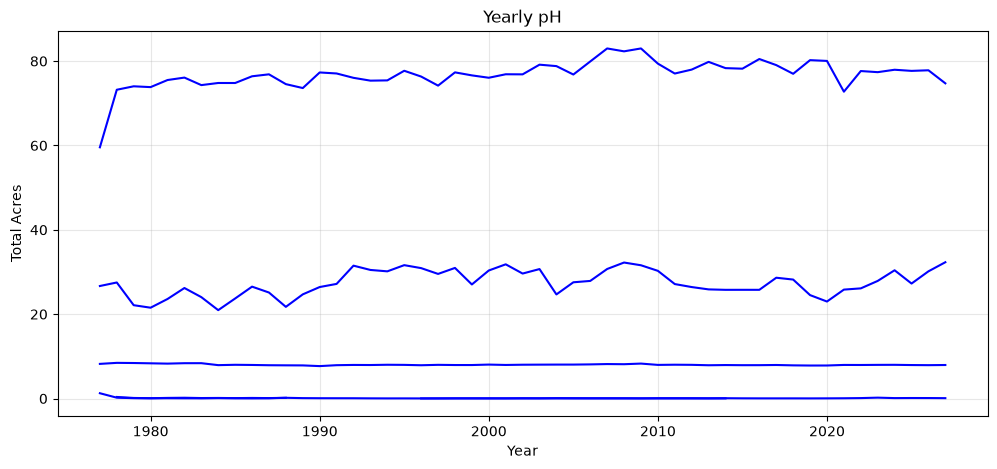

In [72]:
plt.figure(figsize=(12, 5))
plt.plot(yrly_average.index, yrly_average.values, color='blue', linewidth=1.5)
plt.title('Yearly pH')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()

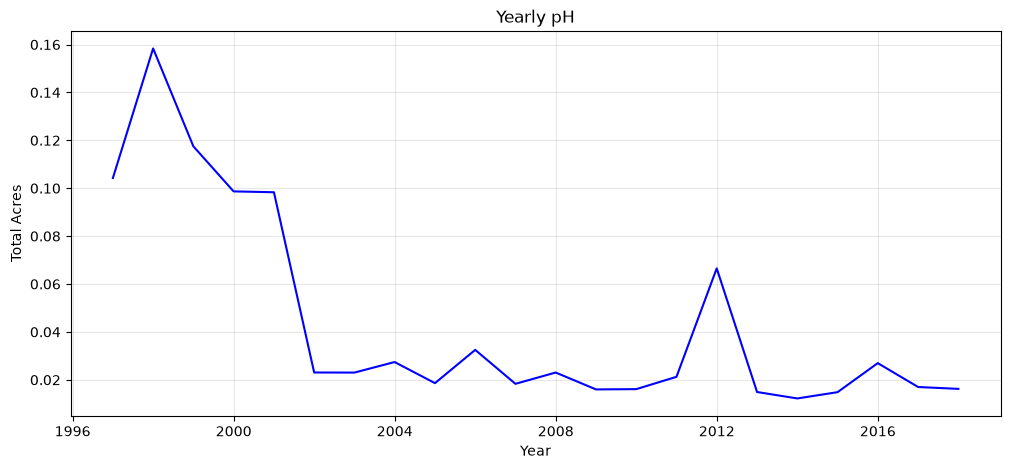

In [77]:
tampa_bay_quality = water_quality.groupby('SampleDate')[['NH4_mgl']].mean().reset_index()
tampa_bay_quality = tampa_bay_quality.set_index('SampleDate').sort_index()
monthly_average = tampa_bay_quality[['NH4_mgl']].resample('YE').mean()
plt.figure(figsize=(12, 5))
plt.plot(monthly_average.index, monthly_average.values, color='blue', linewidth=1.5)
plt.title('Yearly pH')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()

In [79]:
revenue = pd.read_csv('data/Tampa_Bay_Revenue.csv')
revenue

,Year,Net_Investment,Port_Usage_fees,Land_lease,dockage_Cargo,dockage_Cruise,dockage_Other,wharfage_Cargo,wharfage_Cruise,wharfage_Other,Dry_Cargo,Liquid_Cargo,General_Cargo,Cruise_Passenger_Count,Cruise_Revenue
0,2016,581841,36793,11752,5813,1032.0,659,9791,6371.0,8706,4458,8650,1033,813800.0,9879538.0
1,2017,594645,39916,13058,6926,1203.0,229,10561,8041.0,8231,4988,8625,1368,960901.0,11823004.0
2,2018,611124,43603,13058,7402,1277.0,463,11991,8868.0,8356,5488,9329,1389,1043329.0,12876002.0
3,2019,641903,46206,18040,7270,1340.0,845,11521,10178.0,9942,5337,9591,1315,1149289.0,13918893.0
4,2020,645586,37480,18090,7313,668.0,733,11892,4735.0,8767,6193,8665,1319,507920.0,6398069.0
5,2021,661548,35037,23288,8460,NaN,751,13026,NaN,9747,6385,9196,1550,NaN,NaN
6,2022,680034,46100,23605,10262,630.0,1213,12794,4411.0,11274,5415,8849,1890,418156.0,6253298.0
7,2023,705783,59492,25662,11446,1144.0,2279,14266,10791.0,10853,5613,9891,1821,1124057.0,14999919.0
8,2024,730710,60856,26291,11825,1173.0,1394,14426,12066.0,10161,6051,9680,1962,1210292.0,16809968.0
9,2025,790607,70828,31044,11234,1488.0,1742,13734,17744.0,12275,5009,10762,1672,1660315.0,24797103.0


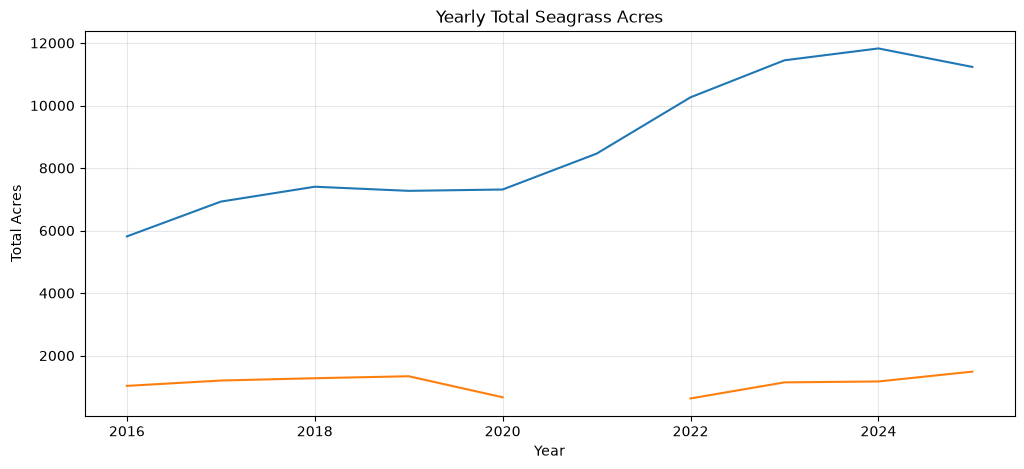

In [82]:
plt.figure(figsize=(12, 5))
plt.plot(revenue['Year'], revenue['dockage_Cargo'])
plt.plot(revenue['Year'], revenue['dockage_Cruise'])
plt.title('Yearly Total Seagrass Acres')
plt.xlabel('Year')
plt.ylabel('Total Acres')
plt.grid(True, alpha=0.3)
plt.show()